In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("flood_risk_dataset_india.csv")

print("Dataset Shape:", df.shape)
df.head()

Saving flood_risk_dataset_india.csv to flood_risk_dataset_india (1).csv
Dataset Shape: (10000, 14)


,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465433,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [2]:
# Dataset information
df.info()

# Check missing values
print("Missing Values:\n", df.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Statistical summary
display(df.describe())

# Remove duplicate rows and handle missing values
df = df.drop_duplicates()
df = df.dropna()

print("Final Dataset Shape:", df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Latitude                10000 non-null  float64
 1   Longitude               10000 non-null  float64
 2   Rainfall (mm)           10000 non-null  float64
 3   Temperature (°C)        10000 non-null  float64
 4   Humidity (%)            10000 non-null  float64
 5   River Discharge (m³/s)  10000 non-null  float64
 6   Water Level (m)         10000 non-null  float64
 7   Elevation (m)           10000 non-null  float64
 8   Land Cover              10000 non-null  object 
 9   Soil Type               10000 non-null  object 
 10  Population Density      10000 non-null  float64
 11  Infrastructure          10000 non-null  int64  
 12  Historical Floods       10000 non-null  int64  
 13  Flood Occurred          10000 non-null  int64  
dtypes: float64(9), int64(3), object(2)
memo

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,22.330627,82.631366,150.015118,29.961401,59.749104,2515.722946,5.017881,4417.138177,5021.468442,0.502000,0.498700,0.505700
std,8.341274,8.389542,86.032127,8.669838,23.142734,1441.706442,2.876579,2530.245421,2882.591520,0.500021,0.500023,0.499993
min,8.000337,68.004575,0.014437,15.000166,20.001339,0.042161,0.002701,1.150340,2.289000,0.000000,0.000000,0.000000
25%,15.143537,75.364428,76.124373,22.405717,39.541778,1284.782376,2.538847,2229.681903,2491.766601,0.000000,0.000000,0.000000
50%,22.283330,82.671007,150.620428,30.000907,59.497375,2530.451944,5.042094,4417.199761,5074.392879,1.000000,0.000000,1.000000
75%,29.460184,89.937897,223.402156,37.413488,80.038163,3767.229862,7.524692,6616.729066,7474.228752,1.000000,1.000000,1.000000
max,36.991813,96.997820,299.970293,44.993681,99.997772,4999.698480,9.996899,8846.894877,9999.169530,1.000000,1.000000,1.000000


Final Dataset Shape: (10000, 14)


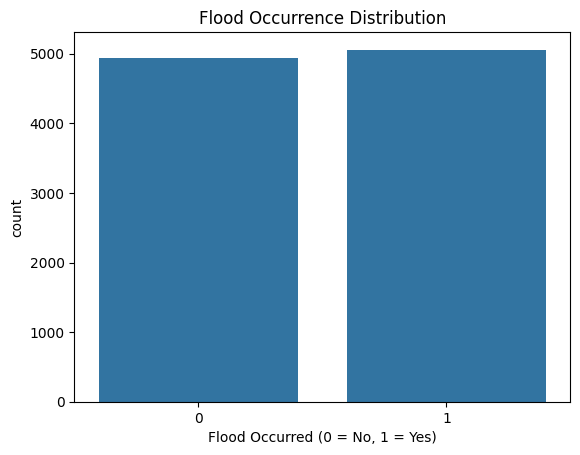

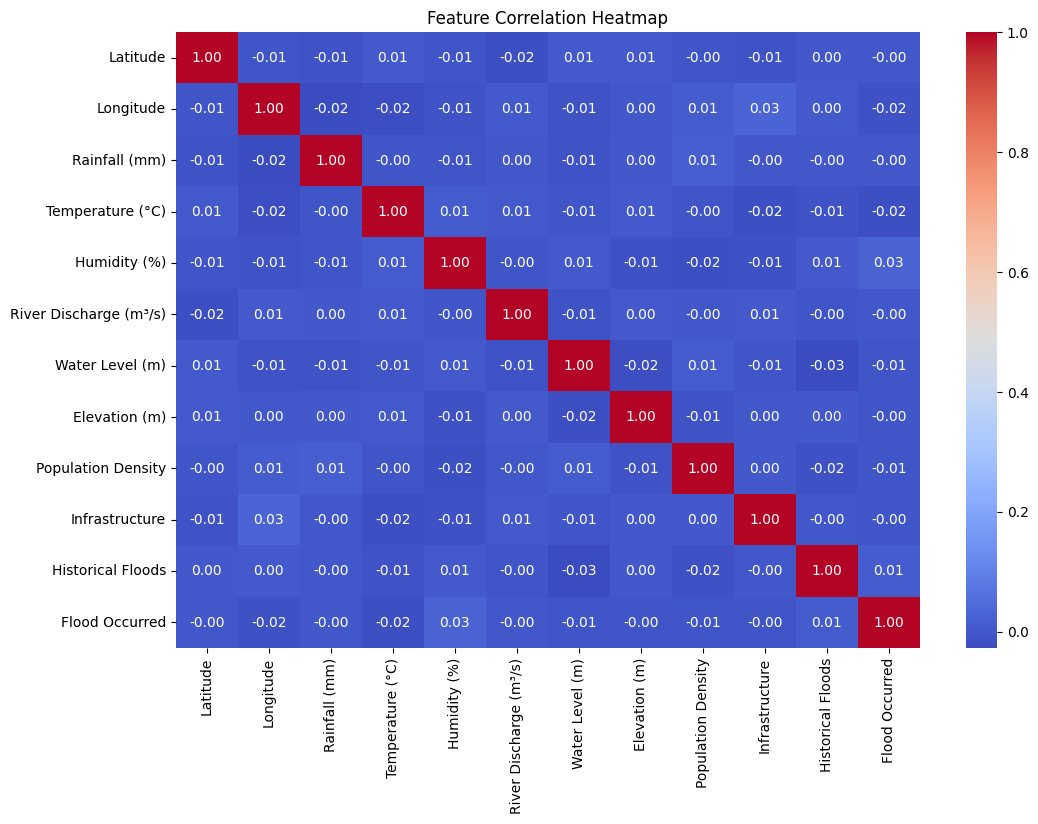

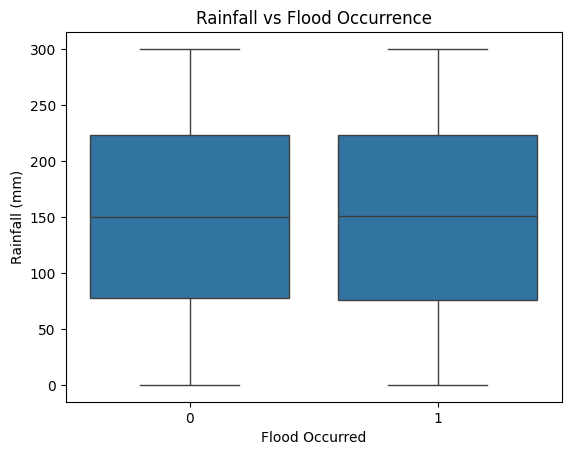

In [3]:
# Flood vs No Flood
sns.countplot(data=df, x="Flood Occurred")
plt.title("Flood Occurrence Distribution")
plt.xlabel("Flood Occurred (0 = No, 1 = Yes)")
plt.show()

# Correlation heatmap for numerical features
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

# Rainfall vs flood occurrence
sns.boxplot(data=df, x="Flood Occurred", y="Rainfall (mm)")
plt.title("Rainfall vs Flood Occurrence")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Input features and target
X = df.drop(columns=["Flood Occurred"])
y = df["Flood Occurred"]

# Identify numerical and categorical columns
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include="number"
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [5]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.4965
Precision: 0.5017
Recall: 0.5727
F1 Score: 0.5349

Classification Report:

              precision    recall  f1-score   support

           0       0.49      0.42      0.45       989
           1       0.50      0.57      0.53      1011

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.49      2000
weighted avg       0.50      0.50      0.49      2000



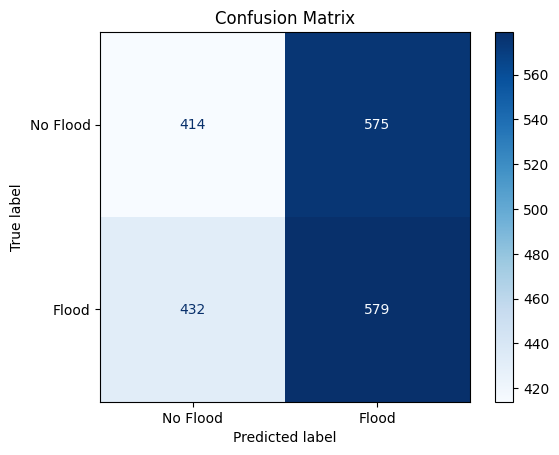

MAE: 0.5035
RMSE: 0.7096
R² Score: -1.0142


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Flood", "Flood"],
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

# Additional regression-style metrics on binary predictions
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R² Score:", round(r2_score(y_test, y_pred), 4))

,Model,Accuracy,F1 Score
0,Logistic Regression,0.4965,0.534873
1,Decision Tree,0.5195,0.523077
2,Random Forest,0.4905,0.493790


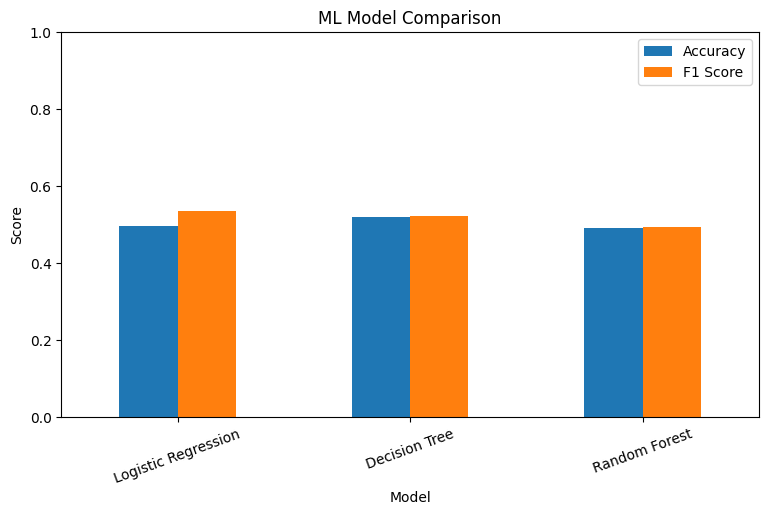

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
)

display(results_df)

results_df.set_index("Model")[["Accuracy", "F1 Score"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("ML Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.show()

In [8]:
new_location = pd.DataFrame([{
    "Latitude": 25.6,
    "Longitude": 85.1,
    "Rainfall (mm)": 180.0,
    "Temperature (°C)": 30.0,
    "Humidity (%)": 85.0,
    "River Discharge (m³/s)": 1200.0,
    "Water Level (m)": 8.0,
    "Elevation (m)": 50.0,
    "Land Cover": "Agricultural",
    "Soil Type": "Clay",
    "Population Density": 1000.0,
    "Infrastructure": 1,
    "Historical Floods": 1
}])

prediction = model.predict(new_location)[0]
probability = model.predict_proba(new_location)[0][1]

print("Predicted Flood Occurrence:", prediction)
print("Predicted Flood Probability:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Model Prediction: Flood")
else:
    print("Model Prediction: No Flood")

Predicted Flood Occurrence: 1
Predicted Flood Probability: 56.45 %
Model Prediction: Flood


In [9]:
import joblib

joblib.dump(model, "flood_risk_model.pkl")
files.download("flood_risk_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>